# **Aprendizado Não Supervisionado** (*Unsupervised Learning*)

## 1. Fundamentos e Limitações da Curadoria de Dados
Atualmente, grandes volumes de dados estão disponíveis na internet para aplicações em Aprendizado de Máquina. Embora os métodos de **Aprendizado Supervisionado** estudados nos capítulos anteriores sejam altamente eficazes na predição de valores futuros a partir de dados históricos, eles apresentam uma limitação operacional evidente: **os dados exigem curadoria prévia**.

Para treinar um modelo supervisionado, um especialista humano precisa rotular manualmente a classe alvo (`y`) de um grande número de instâncias (por exemplo, um botânico precisa classificar previamente a espécie correta de cada flor *Iris*, ou um médico precisa laudar milhares de exames). Esse processo demanda tempo e recursos financeiros elevados, produzindo bases de dados reduzidas quando comparadas ao volume bruto disponível digitalmente.

O **Aprendizado Não Supervisionado** (*Unsupervised Learning*) contorna essa restrição operando diretamente sobre **dados não rotulados** (matriz `X`, sem a presença do vetor alvo/gabarito `y`). Suas duas principais técnicas são:

### 1.1 Agrupamento (*Clustering*)
Uma das tarefas mais diretas que podemos executar em um conjunto de dados sem rótulos é encontrar grupos de dados em nosso conjunto de dados que são semelhantes entre si -- o que chamamos de *clusters*.  

Consiste em identificar grupos naturais (*clusters*) nos quais elementos pertencentes ao mesmo grupo sejam altamente similares entre si, enquanto elementos de grupos distintos sejam dissimilares.  

* **Analogia Prática:** Imagine organizar os lugares das mesas em uma recepção de casamento agrupando convidados por afinidade (família da noiva, amigos de faculdade do noivo, etc.). Definir matematicamente o que significa "ser similar" e onde traçar a fronteira entre grupos em espaços de múltiplas dimensões é o objetivo de algoritmos como **K-Means**, **Propagação de Afinidade** (*Affinity Propagation*), **Mean Shift** e **Modelos de Mistura Gaussiana** (*Gaussian Mixture Models*).

### 1.2 Redução de Dimensionalidade
Quando um conjunto de dados possui dezenas ou milhares de atributos (colunas), torna-se impossível para o ser humano visualizar padrões diretamente, pois nossa percepção espacial limita-se a três dimensões. Os métodos de **Redução de Dimensionalidade** projetam dados de alta dimensão em um espaço de dimensão inferior (como 2D ou 3D), preservando ao máximo a estrutura original da informação. Isso permite tanto a visualização exploratória quanto a escolha adequada de modelos preditivos (verificando, por exemplo, se as classes são separáveis por um hiperplano linear simples).

#### 1.2.1 Análise de Componentes Principais (*Principal Component Analysis* — PCA)

A **Análise de Componentes Principais (PCA)** é uma Transformada Linear Ortogonal que <span style="color:blue;font-weight:bold">converte um conjunto de variáveis possivelmente correlacionadas em um novo conjunto de variáveis linearmente não correlacionadas</span>, denominadas **Componentes Principais**.

É considerada uma técnica **não supervisionada** que transforma dados de alta dimensão em um conjunto menor (redução de dimensionalidade) de variáveis ​​não correlacionadas que capturam a maior parte da variância.

* **Funcionamento**: A PCA baseia-se na **projeção da variância**:

    1. **Ordenação por Variância**: O novo sistema de coordenadas é orientado de modo que a **maior variância** (maior dispersão de informação) dos dados fique projetada na **Primeira Componente Principal**; a segunda maior variância fique na **Segunda Componente Principal**, e assim sucessivamente.

    2. **Restrição de Ortogonalidade**: Cada nova componente adicionada deve ser estritamente ortogonal (perpendicular, ou seja, sem correlação linear) às componentes anteriores.

    3. **Dimensionalidade**: A PCA atua revelando a estrutura interna dos dados ao fornecer uma "sombra" em baixa dimensão dos objetos originais. Ao descartarmos as componentes de baixa variância e mantermos apenas as duas primeiras, reduzimos a dimensionalidade e conseguimos inspecionar problemas complexos em um simples gráfico de dispersão bidimensional (*scatter plot*).

<div style="text-align: center; margin: 20px 0;">
    <img src="https://upload.wikimedia.org/wikipedia/commons/thumb/f/f5/GaussianScatterPCA.svg/500px-GaussianScatterPCA.svg.png"     
         alt="Representação Geométrica do PCA" style="width:35%; max-width:450px; height:auto; border-radius:6px; box-shadow:0 4px 8px rgba(0,0,0,0.15);">  
    <p style="font-size: 0.9em; color: #000000; margin-top: 8px;"><b>Figura 1</b> - Gráfico de dispersão de amostras distribuídas segundo uma distribuição gaussiana multivariada (bivariada), centrada em (1, 3), com desvios padrões 3 na direção (0.878, 0.478) e de 1 na direção ortogonal. As direções representam as Componentes Principais (CP) associadas à amostra.</p>
    <p style="font-size: 0.9em; color: #555; margin-top: 8px;">
        Projeção Ortogonal da <b>PCA</b>: o primeiro eixo captura a direção de maior variância (maior espalhamento) dos dados,<br>    
        e o segundo eixo é perpendicular ao primeiro.
    </p>
</div>

Por não utilizar a classe alvo (vetor `y`) para calcular suas transformações — baseando-se exclusivamente nos valores da matriz de atributos `X` — a PCA é um método de Aprendizado de Máquina **não supervisionado** com duas finalidades primordiais:  
* **Visualização Exploratória**: Projetar dezenas de dimensões em um plano 2D permite mapear a distribuição das instâncias e verificar visualmente quão separáveis são os grupos antes de treinar um classificador.  

* **Extração/Seleção de Características (*Feature Selection*)**: Combate a chamada *Maldição da Dimensionalidade* (*Curse of Dimensionality*). Em vez de treinar um algoritmo com milhares de colunas originais redundantes, aplicamos a PCA para comprimir os dados nas componentes mais informativas e treinamos o modelo supervisionado sobre o novo espaço reduzido.

## 2. Aplicação Prática: Reconhecimento de Dígitos Manuscritos 
### 2.1 Redução de 64 para 2 Dimensões

Para demonstrar o poder da PCA na prática, utilizaremos a base de dados **digits** do pacote `scikit-learn`, composta por imagens de **dígitos decimais manuscritos**, de `0` a `9`, digitalizados em matrizes de **$8 \times 8$ pixels**.

Cada imagem possui **64 atributos numéricos** (intensidade da escala de cinza de cada pixel). Como é impossível para um cientista de dados enxergar um gráfico de 64 dimensões simultaneamente, aplicaremos a **PCA** para reduzir essas 64 colunas em apenas 2 **Componentes Principais**.

Vamos iniciar carregando a base de dados **digits** e inspecionando a sua estrutura interna:

Primeiros 30 dígitos: [0 1 2 3 4 5 6 7 8 9 0 1 2 3 4 5 6 7 8 9 0 1 2 3 4 5 6 7 8 9]
Últimos 30 dígitos:   [4 0 5 3 6 9 6 1 7 5 4 4 7 2 8 2 2 5 7 9 5 4 8 8 4 9 0 8 9 8]
Chaves disponíveis no dataset: ['data', 'target', 'frame', 'feature_names', 'target_names', 'images', 'DESCR']
Dimensão da matriz 'X_digitos' (Amostras x Pixels): (1797, 64)


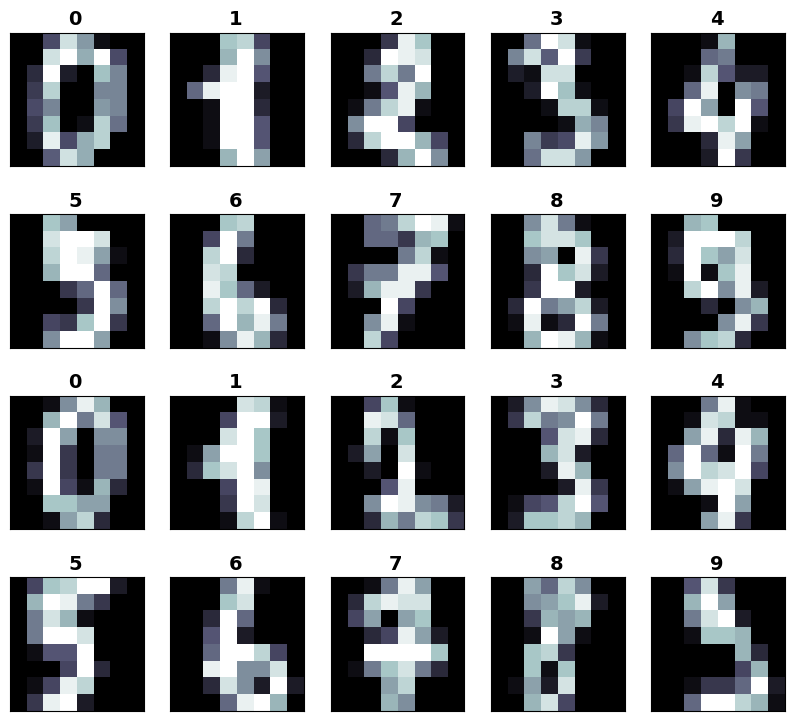

In [73]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

# Carrega o conjunto de dados de dígitos decimais manuscritos
digitos = load_digits()     # dados armazenados em um dicionário
X_digitos, y_digitos = digitos.data, digitos.target
print("Primeiros 30 dígitos:", y_digitos[:30])
print("Últimos 30 dígitos:  ", y_digitos[-30:])
# Exibem as chaves do dicionário de dados 
print("Chaves disponíveis no dataset:", list(digitos.keys()))
print("Dimensão da matriz 'X_digitos' (Amostras x Pixels):", X_digitos.shape)

# Renderiza os 20 primeiros dígitos manuscritos (matrizes 8x8)
def print_digits(images, y, max_n=10, col_graf=2, lin_graf=2):
    # Configura o tamanho da figura em polegadas
    fig = plt.figure(figsize=(2.*col_graf, 2.26*lin_graf))
    i = 0
    while i < max_n and i < images.shape[0]:
        p = fig.add_subplot(lin_graf, col_graf, i + 1, xticks=[], yticks=[])
        p.imshow(images[i], cmap=plt.cm.bone, interpolation='nearest')
        # Rotula a imagem com o valor real (target) correspondente
        p.text(3, -1, str(y[i]), fontsize=14, fontweight='bold')
        i = i + 1
    plt.show()
n_col, n_row = 5, 4
print_digits(digitos.images, digitos.target, max_n=20, col_graf=n_col, lin_graf=n_row)

### 2.2 Projeção Bidimensional com PCA

Vamos definir uma função auxiliar `plot_pca_scatter()`, para traçar o gráfico de dispersão bidimensional com os pontos obtidos com a transformação do PCA (`sklearn.decomposition.PCA`). Coloriremos cada ponto de acordo com o dígito representado (`0` a `9`), apenas para facilitar a inspeção visual de cada dígito.

<div style="background-color: #cfcff8; border-left: 5px solid; border-right: 5px solid #773014; padding: 5px; margin: 15px -15px; border-radius: 10px; color: #5b0137;">
    <p style="color: #6d3651;">⚠️ <b>Observação:</b> Lembre-se de que o vetor gabarito (<code>y_digitos</code>) <b>não é usado no algoritmo PCA</b> usado pelo comando <code>fit_transform(X_digitos)</code>! O algoritmo agrupa os pontos no plano baseando-se unicamente na geometria dos 64 pixels de entrada de cada dígito. As cores no gráfico são usadas apenas para investigar se a nova distribuição encontrada pelo PCA separa naturalmente os diferentes algarismos.</p>
</div>

No `scikit-learn`, a PCA é implementada como um objeto transformador (*transformer*) dentro do módulo `sklearn.decomposition`, que aprende uma quantidade de `n_components` de eixos através do método `fit()` ou `fit_transform()`. Extrairemos as 10 primeiras componentes principais (`n_components=10`) e plotaremos apenas os dois primeiros eixos:

(1797, 10) 
 [ -1.25946645   7.9576113    6.99192297 -15.90610526  23.30686741] 
 [-21.27488348  20.76869896   9.95598641  -3.33246429  -4.26906083]


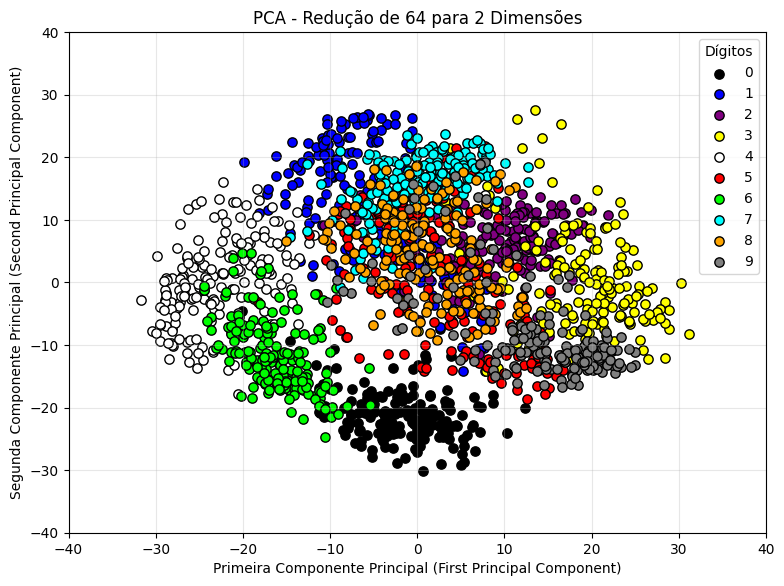

In [89]:
from sklearn.decomposition import PCA
from numpy import arange

def plot_pca_scatter():
    cores = ['black', 'blue', 'purple', 'yellow', 'white', 'red', 'lime', 'cyan', 'orange', 'gray']
    
    plt.figure(figsize=(9, 6.5))
    # Em Python 3, substitui-se xrange() por range()
    for i in range(len(cores)):
        px = -X_pca[:, 0][y_digitos == i]
        py = X_pca[:, 1][y_digitos == i]
        plt.scatter(px, py, c=cores[i], edgecolors='black', s=45, label=str(digitos.target_names[i]))
        
    plt.legend(loc='upper right', title="Dígitos")
    plt.xlabel('Primeira Componente Principal (First Principal Component)')
    plt.ylabel('Segunda Componente Principal (Second Principal Component)')
    plt.title('PCA - Redução de 64 para 2 Dimensões')
    plt.xlim(-40,40); plt.ylim(-40,40)
    plt.grid(True, alpha=0.3)
    plt.show()

# Instanciando o estimador PCA, transformando a matriz 'X_digitos' e gerando o gráfico PCA
estimator = PCA(n_components=10)
X_pca = estimator.fit_transform(X_digitos)
print(X_pca.shape, '\n', X_pca[:5,0], '\n', X_pca[:5,1])
plot_pca_scatter()

In [85]:
# Quantidade de amostras de cada dígito
print("Qtde de dígitos:")
for i in range(0,10):
    print(i, ": ", len(X_pca[:,1][y_digitos==i]), ",  ", sep='', end='')

Qtde de dígitos:
0: 178,  1: 182,  2: 177,  3: 183,  4: 181,  5: 182,  6: 181,  7: 179,  8: 174,  9: 180,  

#### Interpretação do Gráfico de Dispersão
A partir do diagrama bidimensional gerado acima, podemos extrair conclusões diretas sobre a estrutura dos dados antes mesmo de treinar qualquer classificador:

1. **Formação Natural de Agrupamentos (*Clusters*):** À primeira vista, observamos que as 10 classes correspondentes aos dígitos de `0` a `9` agrupam-se em regiões relativamente distintas. A principal exceção é a classe correspondente ao **dígito `5`** (pontos <span style="color:red">vermelhos</span>), cujas amostras encontram-se espalhadas de forma esparsa pelo plano, sobrepondo-se a outras classes.

2. **Dígito `0` Bem Isolado**: No outro extremo, o agrupamento correspondente ao **dígito `0`** (pontos **pretos**, na base inferior) é o mais bem separado de todo o conjunto. Intuitivamente, prevemos que esta será a classe mais fácil de ser distinguida por um classificador supervisionado, devendo apresentar as melhores métricas de avaliação.

3. **Vizinhança Topológica e Semelhança Gráfica**: Classes contíguas (vizinhas no gráfico) correspondem a números com traçados manuscritos semelhantes, indicando onde os classificadores terão maior dificuldade. Por exemplo, os agrupamentos correspondentes aos **dígitos `9`** (<span style="color:#342211">cinza</span>) e `3` (<span style="color:yellow">amarelo</span>) aparecem colados na região direita do gráfico — dada a semelhança de suas curvas superiores e inferiores. Assim, será matematicamente mais difícil separar um `9` de um `3` do que separar um `9` de um `4` (pontos brancos), que estão isolados no extremo esquerdo do gráfico.

### 2.3 Anatomia das Transformações: Visualizando os Autovetores (`components_`)
Para compreender fisicamente o que cada eixo da PCA está medindo nas imagens, podemos extrair as componentes principais diretamente do estimador `estimator` via atributo `.components_`. 

Cada componente é um vetor de 64 pesos (uma matriz $8 \times 8$) utilizado para multiplicar e transformar os pixels originais para o novo espaço reduzido. Vamos remodelar esses 10 componentes para o formato $8 \times 8$ e exibi-los como imagens de calor, usando o seguinte mapa de cores: `jet`.  
<img src="./img/matplotlib_colormaps.png" width="700px">
<img src="./img/matplotlib_colormaps_jet_hot.png" width="700px">

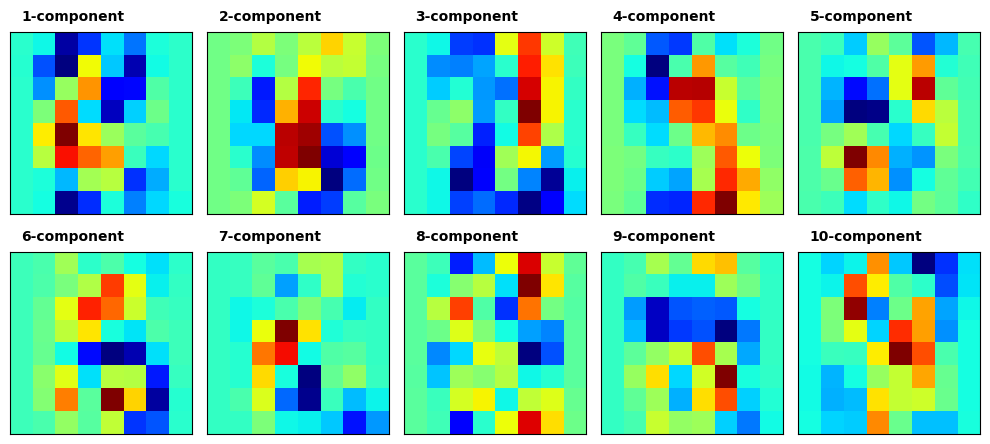

In [91]:
def print_pca_components(images, n_col, n_row):
    plt.figure(figsize=(2. * n_col, 2.26 * n_row))
    for i, comp in enumerate(images):
        plt.subplot(n_row, n_col, i + 1)
        # Remodela o vetor de 64 pesos de volta para uma grade 8x8 pixels
        plt.imshow(comp.reshape((8, 8)), interpolation='nearest', cmap=plt.cm.jet) # plt.cm.hot
        plt.text(0, -1, str(i + 1) + '-component', fontsize=10, fontweight='bold')
        plt.xticks(())
        plt.yticks(())
    plt.tight_layout()
    plt.show()

# Exibindo as matrizes de transformação dos 10 primeiros componentes
print_pca_components(estimator.components_, n_col, n_row)

#### 2.3.1 Revelações da Duas Primeiras Componentes
Ao compararmos as matrizes de pesos da `1-component` e da `2-component` com o gráfico de dispersão anterior, conseguimos desvendar a lógica geométrica do algoritmo:

* **Análise da 1a. Componente** (`1-component` — Eixo Horizontal): No gráfico de dispersão, vimos que o eixo horizontal separa perfeitamente o **dígito `4`** (extrema esquerda, valores negativos baixos) do **dígito `3`** (extrema direita, valores positivos altos). Olhando para a imagem da `1-component`, vemos que as regiões azuladas (pesos positivos altos, à direita) desenham um contorno muito similar ao traçado do número `3`, enquanto as zonas avermelhadas (pesos negativos, à esquerda) coincidem exatamente com as hastes características do número `4`!

* **Análise da 2a. Componente (`2-component` — Eixo Vertical):** Observe que a imagem da `2-component` destaca fortemente a região central da grade $8 \times 8$ (mancha vermelha intensa no meio). O dígito `0` é o único algarismo cujo centro é completamente vazio. Isso explica matematicamente por que o agrupamento de pontos pretos (`0`) ficou isolado na parte mais baixa do eixo vertical no gráfico de dispersão (menores valores para a segunda componente).

> **💡 Síntese para Projetos de Engenharia:**  
> Se adicionássemos a **3a. Componente Principal**, poderíamos plotar um gráfico tridimensional (3D) e separar ainda mais as classes sobrepostas. Na próxima seção, avançaremos para a segunda família de métodos não supervisionados: os **Algoritmos de Agrupamento (*Clustering*)**, onde veremos como o próprio PCA continuará nos auxiliando a visualizar e validar os grupos encontrados!

Nesta primeira etapa, compreendemos a limitação dos dados não rotulados e utilizamos a **Análise de Componentes Principais (PCA)** para reduzir a complexidade de imagens de dígitos decimais manuscritos de 64 dimensões para apenas duas, permitindo a visualização espacial de padrões e a compreensão dos autovetores subjacentes.

* **PARTE 2**: Na próxima etapa responderemos à seguinte questão: *Depois de visualizar e simplificar os dados, como agruparemos automaticamente instâncias similares sem que precisemos dizer à máquina o que é cada elemento*. Entraremos no universo do algoritmos de **Agrupamento** (*Clustering*), começando pelo algoritmo **K-Means**, método de descoberta automática de grupos e modelos probabilísticos (GMM).

# Fontes
* Raúl Garreta & Guillermo Moncecchi; "Learning scikit-learn: Machine Learning in Python"; Nov/2013; Packt Publishing; 118 p.